<a href="https://colab.research.google.com/github/JosueTP249/Tareas_SistemasInteligentes/blob/main/Tarea01_Redes_Neuronales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Tarea 01 - Redes Neuronales

Aquí es un problema de **clasificación binaria**:
la red debe predecir `Transported` (True/False).


#Importar librerias a usar

In [14]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Semillas
tf.keras.utils.set_random_seed(42)

## 1. Cargar los datos

In [15]:

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (8693, 14) | test: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
# Valores faltantes y balance de la variable objetivo
print(train.isna().sum())
print()
print(train["Transported"].value_counts(normalize=True))

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64


## 2. Preprocesamiento
La red solo entiende números, y no puede recibir valores faltantes (`NaN`).
Hay que:
1. Separar `Cabin` en `Deck`, `Num` y `Side` y quitar columnas que no aportan (`PassengerId`, `Name`).
2. Rellenar valores faltantes.
3. Convertir texto a números (one-hot).
4. Normalizar mis datos.


In [4]:
GASTOS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

def preparar(df):
    df = df.copy()


    df[["Deck", "CabinNum", "Side"]] = df["Cabin"].str.split("/", expand=True)
    df["CabinNum"] = pd.to_numeric(df["CabinNum"])


    df["Grupo"] = df["PassengerId"].str.split("_").str[0]
    df["TamGrupo"] = df.groupby("Grupo")["Grupo"].transform("count")


    df.loc[df["CryoSleep"] == True, GASTOS] = 0
    df[GASTOS] = df[GASTOS].fillna(0)
    df["GastoTotal"] = df[GASTOS].sum(axis=1)

    df = df.drop(columns=["PassengerId", "Name", "Cabin", "Grupo"])
    return df

X_train_df = preparar(train.drop(columns="Transported"))
X_test_df = preparar(test)
y = train["Transported"].astype(np.float32).values

X_train_df.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNum,Side,TamGrupo,GastoTotal
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,B,0.0,P,1,0.0
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,F,0.0,S,1,736.0
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,A,0.0,S,2,10383.0
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,A,0.0,S,2,5176.0
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,F,1.0,S,1,1091.0


In [5]:
# Rellenar faltantes
num_cols = X_train_df.select_dtypes(include="number").columns
cat_cols = ["HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side"]

medianas = X_train_df[num_cols].median()
modas = X_train_df[cat_cols].mode().iloc[0]

def rellenar(df):
    df = df.copy()
    df[num_cols] = df[num_cols].fillna(medianas)
    df[cat_cols] = df[cat_cols].fillna(modas)
    df[["CryoSleep", "VIP"]] = df[["CryoSleep", "VIP"]].astype(bool).astype(int)
    return df

X_train_df = rellenar(X_train_df)
X_test_df = rellenar(X_test_df)

# One-hot para HomePlanet, Destination, Deck, Side
X_train_df = pd.get_dummies(X_train_df, columns=["HomePlanet", "Destination", "Deck", "Side"], dtype=int)
X_test_df = pd.get_dummies(X_test_df, columns=["HomePlanet", "Destination", "Deck", "Side"], dtype=int)

# Aquí aseguro que test tenga las mismas columnas y en el mismo orden
X_test_df = X_test_df.reindex(columns=X_train_df.columns, fill_value=0)

print("Variables de entrada:", X_train_df.shape[1])
print("NaN restantes:", X_train_df.isna().sum().sum(), X_test_df.isna().sum().sum())
list(X_train_df.columns)

Variables de entrada: 27
NaN restantes: 0 0


/tmp/ipykernel_923/3052380997.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[cat_cols] = df[cat_cols].fillna(modas)
/tmp/ipykernel_923/3052380997.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[cat_cols] = df[cat_cols].fillna(modas)


['CryoSleep',
 'Age',
 'VIP',
 'RoomService',
 'FoodCourt',
 'ShoppingMall',
 'Spa',
 'VRDeck',
 'CabinNum',
 'TamGrupo',
 'GastoTotal',
 'HomePlanet_Earth',
 'HomePlanet_Europa',
 'HomePlanet_Mars',
 'Destination_55 Cancri e',
 'Destination_PSO J318.5-22',
 'Destination_TRAPPIST-1e',
 'Deck_A',
 'Deck_B',
 'Deck_C',
 'Deck_D',
 'Deck_E',
 'Deck_F',
 'Deck_G',
 'Deck_T',
 'Side_P',
 'Side_S']

In [16]:
# (80% entrenar / 20% validar)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_df.values.astype(np.float32), y,
    test_size=0.2, random_state=42, stratify=y
)

# Normalizo fit solo con los datos de entrenamiento
scaler = StandardScaler()
scaler.fit(X_tr)

X_tr_norm = scaler.transform(X_tr)
X_val_norm = scaler.transform(X_val)
X_test_norm = scaler.transform(X_test_df.values.astype(np.float32))

print(X_tr_norm.shape, X_val_norm.shape, X_test_norm.shape)

(6954, 27) (1739, 27) (4277, 27)


## 3. Red neuronal
Le ponemos capas ocultas con `relu` y cerramos con una neurona `sigmoid` para calcular de una vez la probabilidad de que se nos vayan de viaje `(Transported = True)`.

In [7]:
n_entradas = X_tr_norm.shape[1]

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(n_entradas,)),
    tf.keras.layers.Dense(units=32, activation="relu"),
    tf.keras.layers.Dense(units=16, activation="relu"),
    tf.keras.layers.Dense(units=1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,441 (5.63 KB)

 Trainable params: 1,441 (5.63 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [9]:
historial = model.fit(
    X_tr_norm, y_tr,
    validation_data=(X_val_norm, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True)],
    verbose=0
)

print("Épocas entrenadas:", len(historial.history["loss"]))

Épocas entrenadas: 32


## 4. Evaluación

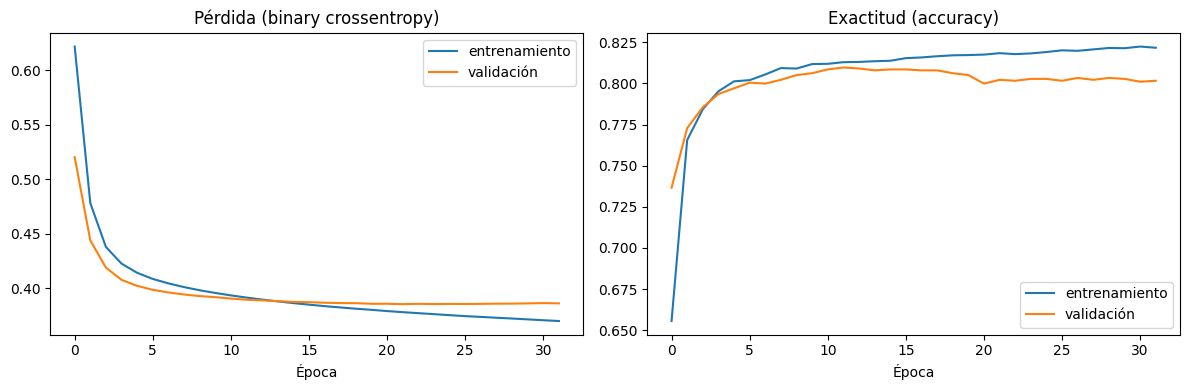

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(historial.history["loss"], label="entrenamiento")
ax[0].plot(historial.history["val_loss"], label="validación")
ax[0].set_title("Pérdida (binary crossentropy)")
ax[0].set_xlabel("Época"); ax[0].legend()

ax[1].plot(historial.history["accuracy"], label="entrenamiento")
ax[1].plot(historial.history["val_accuracy"], label="validación")
ax[1].set_title("Exactitud (accuracy)")
ax[1].set_xlabel("Época"); ax[1].legend()

plt.tight_layout()
plt.show()

In [11]:
loss, acc = model.evaluate(X_val_norm, y_val, verbose=0)
print(f"Validación -> pérdida: {loss:.4f} | accuracy: {acc:.4f}")

Validación -> pérdida: 0.3855 | accuracy: 0.8022


## 5. Predicciones sobre `test.csv`

In [12]:
# La salida es una probabilidad; con umbral 0.5 la convertimos a True/False
probabilidades = model.predict(X_test_norm, verbose=0).flatten()
predicciones = probabilidades >= 0.5

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Transported": predicciones
})
submission.to_csv("submission.csv", index=False)
submission.head()

,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False


In [13]:
# Predicción para un pasajero nuevo
# Se toma el primer pasajero de test como ejemplo
pasajero = X_test_norm[[0]]
prob = model.predict(pasajero, verbose=0)[0][0]
print(f"Probabilidad de ser transportado: {prob:.2%} -> {'Sí' if prob >= 0.5 else 'No'}")

Probabilidad de ser transportado: 32.49% -> No
